Part a

In [1]:
import pandas as pd
import os

DATASET_PATH = r'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Pattern Recognition/Assignments/HW5/Question/Input/P4/BBC News Train.csv'
bbc_data = pd.read_csv(DATASET_PATH)
print(bbc_data.head())
print(bbc_data.info())

   ArticleId                                               Text  Category
0       1833  worldcom ex-boss launches defence lawyers defe...  business
1        154  german business confidence slides german busin...  business
2       1101  bbc poll indicates economic gloom citizens in ...  business
3       1976  lifestyle  governs mobile choice  faster  bett...      tech
4        917  enron bosses in $168m payout eighteen former e...  business
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1490 entries, 0 to 1489
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ArticleId  1490 non-null   int64 
 1   Text       1490 non-null   object
 2   Category   1490 non-null   object
dtypes: int64(1), object(2)
memory usage: 35.0+ KB
None


Part b

In [2]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
import string

nltk.download('punkt')
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess_text(text):
    # Tokenization
    tokens = word_tokenize(text.lower())
    # Removing punctuation and stopwords, and apply stemming
    tokens = [stemmer.stem(word) for word in tokens if word.isalnum() and word not in stop_words]
    return ' '.join(tokens)

# Applying preprocessing to each row
bbc_data['Processed_Text'] = bbc_data['Text'].apply(preprocess_text)

C:\Program Files\Anaconda\lib\site-packages\scipy\__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.25.0
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\TamirLand\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\TamirLand\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Part c

In [3]:
from gensim.models import KeyedVectors

# Loading the pre-trained word2vec model from local path
model_path = r'C:/Users/TamirLand/Downloads/GoogleNews-vectors-negative300.bin'
word2vec = KeyedVectors.load_word2vec_format(model_path, binary=True)

# Generating embeddings by averaging word vectors
def get_text_embedding(text):
    words = text.split()
    vectors = [word2vec[word] for word in words if word in word2vec]
    return sum(vectors) / len(vectors) if vectors else [0] * 300

bbc_data['Embedding'] = bbc_data['Processed_Text'].apply(get_text_embedding)

Part d

In [4]:
from sklearn.decomposition import PCA
import numpy as np

embeddings = np.array(bbc_data['Embedding'].tolist())
# Handle cases where embeddings may have inconsistent lengths
valid_embeddings = np.array([emb for emb in embeddings if len(emb) == 300])
pca = PCA(n_components=50)
reduced_embeddings = pca.fit_transform(valid_embeddings)

Part e

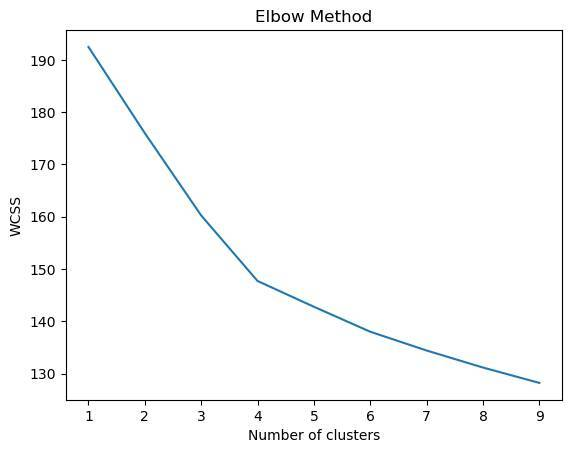

In [9]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

if len(reduced_embeddings) == 0:
    raise ValueError("Reduced embeddings are empty. Check the preprocessing steps.")

# Determining the optimal number of clusters using the Elbow Method
wcss = []
for i in range(1, 11):
    try:
        kmeans = KMeans(n_clusters=i, random_state=42, n_init=10, max_iter=300)
        kmeans.fit(reduced_embeddings)
        wcss.append(kmeans.inertia_)
    except Exception as e:
        print(f"Error at cluster {i}: {e}")
if len(wcss) > 0:
    plt.plot(range(1, len(wcss) + 1), wcss)
    plt.xlabel('Number of clusters')
    plt.ylabel('WCSS')
    plt.title('Elbow Method')
    plt.show()
else:
    print("WCSS list is empty. No valid clustering results.")

# Applying K-Means with the optimal number of clusters (e.g., 5 based on the elbow method)
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10, max_iter=300)
kmeans_labels = kmeans.fit_predict(reduced_embeddings)
bbc_data['KMeans_Cluster'] = kmeans_labels

Part h

In [6]:
from sklearn.metrics import silhouette_score

try:
    silhouette_kmeans = silhouette_score(reduced_embeddings, kmeans_labels)
    print(f'Silhouette Score (KMeans): {silhouette_kmeans}')
except ValueError:
    print("Silhouette Score cannot be computed with the given clustering.")

Silhouette Score (KMeans): 0.1631978452205658


Part i

In [7]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari_kmeans = adjusted_rand_score(bbc_data['Category'], kmeans_labels)
nmi_kmeans = normalized_mutual_info_score(bbc_data['Category'], kmeans_labels)
print(f'KMeans - ARI: {ari_kmeans}, NMI: {nmi_kmeans}')
# Save final results
bbc_data.to_csv('bbc_news_clusters.csv', index=False)

KMeans - ARI: 0.7270107786302346, NMI: 0.740515674184794
